# 从零开始 · 单城全流程演示(南昌·八一广场)

> 目标:选一座**不在既有十五城之列**的社区,从第一次 API 调用开始,完整走一遍
> 生产算法并展示全部中间结果。预算护栏 ≤500 对 / ≤120 次请求;重跑本 notebook
> 因持久缓存而几乎零消耗(二跑零调用是产品特性,见 docs/12)。

流程总览(与 `experiments/pipeline.py` 同构,此处逐步展开):
```text
S1 geocode 定中心 → S2 仪器自检 → S3 8向起步二分(tol50)
→ S4 弦规则加密(实测超时证据/θ≥30°) → S5 mid 探针一轮
→ S6 250m 真值格点 → S7 指标(F1/IoU) → S8 时间场重建(Delaunay+弦约束)
→ S9 多15min点/复通带检查 → S10 成图落盘 → S11 台账结算
```

In [1]:
# S0 准备:客户端、缓存、台账
import os, sys, json, math, sqlite3, time
import pandas as pd
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..', '..')))
from core import baidu_client as bc          # 直连客户端(SN/IP 白名单,.env 提供 AK)
from core import cache as wcache             # (origin,dest) 持久缓存 cache.db
from core.coord import dest_at, bd09_to_wgs84
TH = 900                                      # 15 min

DB = os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'experiments', 'logs', 'calls.db'))    # 台账
CDB = os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'experiments', 'logs', 'cache.db'))   # 步行缓存
T0 = time.strftime('%Y-%m-%dT%H:%M:%S')
def ledger():
    with sqlite3.connect(DB) as c:
        return c.execute("SELECT COUNT(*), COALESCE(SUM(n_pairs),0) FROM calls WHERE ts>=?",
                         (T0,)).fetchone()
def measure(center, pts, eid="DEMO_NC"):
    """批量测时(≤50对/请求),写缓存,实时退避;返回 [duration,...]"""
    out = []
    for i in range(0, len(pts), 50):
        chunk = pts[i:i+50]
        todo = [p for p in chunk if wcache.get(center, p) is None]
        if todo:
            for attempt in range(4):
                r = bc.routematrix("walking", [center], todo, experiment_id=eid)
                if r.ok: break
                if r.status == 401 and attempt < 3:
                    time.sleep([15,30,60][attempt]); continue
                if r.status == 302:
                    print(f"  [配额] 302 {r.message} —— 优雅降级:跳过 {len(todo)} 个新探针(已有缓存仍可用)")
                    return out + [None] * (len(pts) - len(out))
                raise RuntimeError(f"matrix {r.status} {r.message}")
            for p, it in zip(todo, bc.matrix_items(r)):
                wcache.put(center, p, it["duration_s"], it.get("distance_m"))
        out += [wcache.get(center, p)[0] for p in chunk]
    return out
print("客户端就绪;起始台账:", ledger())

客户端就绪;起始台账: (0, 0)


In [2]:
# S1 geocode:地址 → 中心(bd09)
r = bc.geocode("南昌市东湖区八一广场", experiment_id="DEMO_NC")
assert r.ok, r.message
loc = r.data["result"]["location"]
CENTER = (loc["lat"], loc["lng"])
print(f"中心(bd09): {CENTER[0]:.6f}, {CENTER[1]:.6f}  级别: {r.data['result'].get('level')}")

中心(bd09): 28.680175, 115.910978  级别: 休闲娱乐


In [3]:
# S2 仪器自检:单发步行算路 + 批量矩阵(50 对/请求)各一次
p1 = dest_at(CENTER[1], CENTER[0], 0, 300)
r1 = bc.direction("walking", CENTER, p1, experiment_id="DEMO_NC")
print(f"单发 direction: {r1.duration_s}s / {r1.distance_m}m(直线 300m)")
ps = [dest_at(CENTER[1], CENTER[0], b*22.5, 400) for b in range(16)]
ts = measure(CENTER, ps)
print(f"批量 matrix 16 方位@400m: {ts}")
print("台阶:", ledger())

单发 direction: 394s / 443m(直线 300m)
批量 matrix 16 方位@400m: [426.0, 509.0, 551.0, 651.0, 455.0, 812.0, 491.0, 403.0, 532.0, 854.0, 518.0, 487.0, 621.0, 485.0, 500.0, 525.0]
台阶: (2, 2)


## S3 等时圈:8 向起步 × 二分(tol 50m)

每个方位在 [200,1400]m 上二分,15min 边界定位到 ±25m;
单探针缺失即停(截断≠成功)。所有探针进缓存,可幂等重跑。

In [4]:
def bisect_ray(center, b, lo=200.0, hi=1400.0, tol=50.0):
    p_at = lambda d: dest_at(center[1], center[0], b, d)
    ok = 0
    while hi - lo > tol:
        m = (lo + hi) / 2
        row = wcache.get(center, p_at(m))
        t = row[0] if row else measure(center, [p_at(m)])[0]
        if t is None: return None          # 配额/数据缺失:不产生假半径
        if t <= TH: lo = m
        else: hi = m
    return (lo + hi) / 2

radii = {b*45.0: bisect_ray(CENTER, b*45.0) for b in range(8)}
for b, r in sorted(radii.items()):
    print(f"  {b:5.1f}°  r={r:6.1f}m")
print(f"8 向完成,半径 {min(radii.values()):.0f}-{max(radii.values()):.0f}m,各向异性 "
      f"{max(radii.values())/min(radii.values()):.2f} | 台账:", ledger())

    0.0°  r= 856.2m
   45.0°  r= 706.2m
   90.0°  r= 931.2m
  135.0°  r= 818.8m
  180.0°  r= 706.2m
  225.0°  r= 743.8m
  270.0°  r= 781.2m
  315.0°  r= 743.8m
8 向完成,半径 706-931m,各向异性 1.32 | 台账: (2, 2)


## S4 弦规则加密:违规证据 or θ≥30° → 弦中点插向

- **违规证据**:该扇区内已有实测"超时点"落在当前多边形内(弦外凸过头)
- 与 E10/十六城同一条规则;新向半径=该向真二分(不是插值)

In [5]:
def r_at(brg, rr):
    ks = sorted(rr)
    i = 0
    for j in range(len(ks)):
        if ks[j] <= brg: i = j
    b0, b1 = ks[i], ks[(i+1) % len(ks)]
    db = (b1-b0) % 360 or 360
    t = ((brg-b0) % 360) / db
    return rr[b0]*(1-t) + rr[b1]*t

def viol_evidence(center, rr):
    klat, klng = 111320.0, 111320.0*math.cos(math.radians(center[0]))
    rows = sqlite3.connect(CDB).execute(
        "SELECT d_lat,d_lng,duration_s FROM walk_times").fetchall()
    ev = []
    for dlat, dlng, dur in rows:
        if dur is None: continue
        dd = math.hypot((dlat-center[0])*klat, (dlng-center[1])*klng)
        if dd < 1e-9 or dd > 1500: continue          # 只保留本社区范围内的测点
        bb = math.degrees(math.atan2((dlng-center[1])*klng, (dlat-center[0])*klat)) % 360
        ev.append((bb, dd, dur))
    return ev

for rd in range(6):
    ks = sorted(radii)
    ev = viol_evidence(CENTER, radii)
    inserts = []
    for a, b in zip(ks, ks[1:]+[ks[0]+360]):
        a0, arc = a % 360, (b-a) % 360 or 360
        if arc < 1e-6: continue
        mb = ((a+b)/2) % 360
        viol = any(((bb-a0)%360) < arc and dd < r_at(bb, radii)
                   for bb, dd, dur in ev if dur > TH and dd < 1500)
        if (viol or arc >= 30) and not any(abs(mb-x) < 0.6 or abs(mb-x-360) < 0.6 for x in radii):
            inserts.append(round(mb, 2))
    if not inserts: break
    for mb in inserts:
        v = bisect_ray(CENTER, mb)
        if v is not None: radii[mb] = v
    print(f"第{rd+1}轮 插向 {len(inserts)} 条(有效 {sum(1 for x in inserts if x in radii)})→ k={len(radii)}")
print(f"收敛 k={len(radii)} | 台账:", ledger())

第1轮 插向 8 条(有效 8)→ k=16


第2轮 插向 7 条(有效 7)→ k=23
第3轮 插向 8 条(有效 8)→ k=31


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)
第4轮 插向 10 条(有效 9)→ k=40


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)
第5轮 插向 11 条(有效 8)→ k=48


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)
第6轮 插向 13 条(有效 9)→ k=57
收敛 k=57 | 台账: (19, 19)


## S5 mid 探针一轮(防线 1):每条弦中点 0.97r 处实测

mid > 15min ⇒ 弦外凸(凹口被弦盖住)→ 该方位插向重二分。

In [6]:
ks = sorted(radii)
bad = []
for a, b in zip(ks, ks[1:]+[ks[0]+360]):
    mb = ((a+b)/2) % 360
    p = dest_at(CENTER[1], CENTER[0], mb, r_at(mb, radii)*0.97)
    row = wcache.get(CENTER, p)
    t = row[0] if row else measure(CENTER, [p])[0]
    if t is not None and t > TH:
        bad.append(round(mb, 1))
print("mid 违规:", bad if bad else "无 ✓(一致)")
for mb in bad:
    v = bisect_ray(CENTER, mb)
    if v is not None: radii[mb] = v
if bad: print(f"插向后 k={len(radii)}(配额内有效 {sum(1 for x in bad if x in radii)}/{len(bad)})")
print("台账:", ledger())

  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


...

  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


mid 违规: [24.6, 64.7, 207.8, 260.2, 348.4]


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)
插向后 k=61(配额内有效 4/5)
台账: (40, 40)


## S5b 小角度弦验证(增强:径向夹角小的边界)

**问题**:相邻射线夹角小(arc≤22.5°)而半径差大时,多边形"边"是一段陡弦——
径向 mid 探针(沿半径)测不到弦横向的对错,典型如 348.75°=379m vs 邻 706/856 的窄刺。
**规则**(边级验证,而非径向):
- 候选弦:arc≤22.5° 且(Δr>80m 或 arc≤11.25°)
- 在**边中点 C_mid(两端点线性中点)**实测:C_mid 超时 ⇒ 边跨过不可达区(凹口更深);
  1.06·C_mid 可达 ⇒ 边外仍有可达(凸段漏画)——两种都触发弦中点方位插向(tol25)重二分。

In [7]:
# S5b 小角度弦验证(live)
kcos_b = math.cos(math.radians(CENTER[0]))
for rd in range(3):
    ks = sorted(radii)
    ins = []
    for a, b in zip(ks, ks[1:]+[ks[0]+360]):
        arc = (b-a) % 360 or 360
        dz = abs(radii[a % 360] - radii[b % 360])
        if not (arc <= 22.5 and (dz > 80 or arc <= 11.25)):
            continue
        mb = ((a+b)/2) % 360
        if any(abs(mb-x) < 0.6 or abs(mb-x-360) < 0.6 for x in radii):
            continue
        pa = dest_at(CENTER[1], CENTER[0], a % 360, radii[a % 360])
        pb = dest_at(CENTER[1], CENTER[0], b % 360, radii[b % 360])
        cm = ((pa[0]+pb[0])/2, (pa[1]+pb[1])/2)
        dd = math.hypot((cm[0]-CENTER[0])*111320, (cm[1]-CENTER[1])*111320*kcos_b)
        row = wcache.get(CENTER, cm); t1 = row[0] if row else measure(CENTER, [cm])[0]
        cm2 = dest_at(CENTER[1], CENTER[0], mb, dd*1.06)
        row = wcache.get(CENTER, cm2); t2 = row[0] if row else measure(CENTER, [cm2])[0]
        why = ('凹' if (t1 is not None and t1 > TH) else
               ('凸' if (t2 is not None and t2 <= TH) else ''))
        if why:
            ins.append((round(mb, 2), why))
    if not ins:
        print("S5b:小角度弦边验证一致 ✓")
        break
    ok_ins = []
    for mb, why in ins:
        v = bisect_ray(CENTER, mb, tol=25.0)
        if v is not None:
            radii[mb] = v; ok_ins.append((mb, why))
    if not ok_ins:
        print("S5b:配额/缓存不足,本轮插向未落地(如实)")
        break
    print(f"S5b 第{rd+1}轮:插向 {ok_ins} → k={len(radii)}")
print(f"k={len(radii)} | 台账:", ledger())

  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


...

  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)


  [配额] 302 天配额超限，限制访问 —— 优雅降级:跳过 1 个新探针(已有缓存仍可用)
S5b:配额/缓存不足,本轮插向未落地(如实)
k=65 | 台账: (111, 111)


In [8]:
# 落盘:与十五城同 schema,可直接并入地图/指标管线
out = {"city": "南昌·八一广场", "type": "省会广场商圈(演示城)",
       "center": list(CENTER), "eid": "DEMO_NC",
       "rays": len(radii),
       "anisotropy": round(max(radii.values())/max(1e-9, min(radii.values())), 2),
       "radius_range": [round(min(radii.values())), round(max(radii.values()))],
       "metrics": {"iou": None, "truth_spacing": 250},
       "radii": {f"{b:.2f}": round(v, 1) for b, v in sorted(radii.items())}}
fp_out = os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'experiments',
                                      'results', 'e10_boundary', 'e10x_nanchang.json'))
json.dump(out, open(fp_out, 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
print("已落盘", fp_out)

已落盘 C:\project\15min_life_cycle\experiments\results\e10_boundary\e10x_nanchang.json


## S5c 离线近似边验证(零 API,配额耗尽时的筛查层)

对小角度候选弦,取缓存场中距"边中点 C_mid"最近的实测点(≤80m 才采信):
- 最近点超时 ⇒ 边大概率跨不可达区(凹);最近点可达且距边 ≥1.06 系数外 ⇒ 疑漏凸。
标注"近似"——live 版(S5b)待配额恢复后执行。

In [9]:
# S5c 离线近似验证
sq = sqlite3.connect(CDB).execute(
    "SELECT d_lat,d_lng,duration_s FROM walk_times WHERE o_lat BETWEEN 28.6 AND 28.76").fetchall()
kcos_c = math.cos(math.radians(CENTER[0]))
ks = sorted(radii)
print(f"{'弦':>16s} {'arc':>5s} {'Δr':>5s}  边中点判定(最近实测点)")
for a, b in zip(ks, ks[1:]+[ks[0]+360]):
    arc = (b-a) % 360 or 360
    dz = abs(radii[a % 360] - radii[b % 360])
    if not (arc <= 22.5 and (dz > 80 or arc <= 11.25)):
        continue
    pa = dest_at(CENTER[1], CENTER[0], a % 360, radii[a % 360])
    pb = dest_at(CENTER[1], CENTER[0], b % 360, radii[b % 360])
    cm = ((pa[0]+pb[0])/2, (pa[1]+pb[1])/2)
    best, bd = None, 1e9
    for dlat, dlng, dur in sq:
        d2 = math.hypot((dlat-cm[0])*111320, (dlng-cm[1])*111320*kcos_c)
        if d2 < bd: bd, best = d2, dur
    if bd > 80:
        verdict = f"无近点({bd:.0f}m)→ 待 live 验证"
    elif best > TH:
        verdict = f"凹({bd:.0f}m 处实测 {best:.0f}s>15min)"
    else:
        verdict = f"边可信({bd:.0f}m 处 {best:.0f}s)"
    print(f"{a%360:7.1f}-{b%360:6.1f}° {arc:5.1f} {dz:5.0f}m  {verdict}")

               弦   arc    Δr  边中点判定(最近实测点)
    0.0-  11.2°  11.2    47m  边可信(80m 处 808s)
   11.2-  22.5°  11.2   216m  边可信(58m 处 736s)
   22.5-  23.2°   0.7     0m  边可信(18m 处 633s)
   23.2-  23.9°   0.7     0m  边可信(18m 处 679s)
   23.9-  24.6°   0.7    75m  凹(17m 处实测 1502s>15min)
   24.6-  25.3°   0.7     0m  边可信(10m 处 638s)
   25.3-  26.0°   0.7     0m  边可信(3m 处 638s)
   26.0-  26.7°   0.7    38m  边可信(3m 处 748s)
   26.7-  27.4°   0.7     0m  凹(6m 处实测 1473s>15min)
   27.4-  28.1°   0.7     0m  凹(12m 处实测 1473s>15min)
   28.1-  30.9°   2.8     0m  边可信(0m 处 748s)
   30.9-  33.8°   2.8    38m  边可信(14m 处 734s)
   33.8-  39.4°   5.6    38m  边可信(29m 处 774s)
   39.4-  45.0°   5.6    75m  边可信(35m 处 835s)
   45.0-  50.6°   5.6     0m  边可信(0m 处 876s)
   50.6-  53.4°   2.8     0m  边可信(0m 处 864s)
   53.4-  54.1°   0.7     0m  边可信(4m 处 871s)
   54.1-  54.8°   0.7    38m  边可信(4m 处 871s)
   54.8-  55.5°   0.7     0m  边可信(19m 处 871s)
   55.5-  56.2°   0.7     0m  边可信(19m 处 893s)
   56.2-  59.1°   2.8   

## S6 真值格点(250m × ±1km = 81 点)与 S7 指标

独立于射线的等距网格实测,作为该城评估基准;多边形分类 F1/IoU当场可算。

In [10]:
def grid(spacing, half):
    pts = []
    for i in range(-half//spacing, half//spacing+1):
        lat0, lng0 = dest_at(CENTER[1], CENTER[0], 0, i*spacing)
        for j in range(-half//spacing, half//spacing+1):
            pts.append(dest_at(lng0, lat0, 90, j*spacing))
    return pts

g = grid(250, 1000)
tg = measure(CENTER, g)
kcos = math.cos(math.radians(CENTER[0]))
def polar(p):
    dd = math.hypot((p[0]-CENTER[0])*111320, (p[1]-CENTER[1])*111320*kcos)
    bb = math.degrees(math.atan2((p[1]-CENTER[1])*111320*kcos, (p[0]-CENTER[0])*111320)) % 360
    return dd, bb
yt = [t <= TH for t in tg]
yp = [polar(p)[0] < r_at(polar(p)[1], radii) for p in g]
tp = sum(1 for a,b in zip(yt,yp) if a and b)
fp = sum(1 for a,b in zip(yt,yp) if b and not a)
fn = sum(1 for a,b in zip(yt,yp) if a and not b)
prec, rec = tp/max(1,tp+fp), tp/max(1,tp+fn)
print(f"F1={2*prec*rec/max(1e-9,prec+rec):.3f}  IoU={tp/max(1,tp+fp+fn):.3f}  (FP={fp} FN={fn}, n={len(g)})")
print("台账:", ledger())

F1=0.982  IoU=0.966  (FP=0 FN=1, n=81)


台账: (111, 111)


## S8 时间场重建:Delaunay 线性插值 + 弦约束(E6 选型)

黑线=50m 分辨率重建场 15min 等值线;格点超出该向边界 +80m 置 NaN(防稀疏扇区外推)。

In [11]:
import numpy as np
from scipy.interpolate import griddata
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

field = {}
for (dlat, dlng, dur) in sqlite3.connect(CDB).execute(
        "SELECT d_lat,d_lng,duration_s FROM walk_times").fetchall():
    if dur is None: continue
    d0 = math.hypot((dlat-CENTER[0])*111320, (dlng-CENTER[1])*111320*kcos)
    if d0 < 1500:
        field[(round(dlat,6), round(dlng,6))] = dur
fpts = np.array(list(field.keys())); fvals = np.array(list(field.values()))
gx, gy = [], []
for i in range(-20, 21):
    for j in range(-20, 21):
        p = dest_at(CENTER[1], CENTER[0],
                    math.degrees(math.atan2(j, i)) if (i or j) else 0, math.hypot(i, j)*50)
        gx.append(p[1]); gy.append(p[0])
gz = griddata(fpts, fvals, np.column_stack([gy, gx]), method="linear")
for k2 in range(len(gz)):
    ddx = math.hypot((gy[k2]-CENTER[0])*111320, (gx[k2]-CENTER[1])*111320*kcos)
    bbx = math.degrees(math.atan2((gx[k2]-CENTER[1])*111320*kcos, (gy[k2]-CENTER[0])*111320)) % 360
    if ddx > r_at(bbx, radii) + 80:
        gz[k2] = np.nan
print(f"场样本 {len(field)} 点;重建格 {len(gz)},弦约束后有效 {np.sum(~np.isnan(gz))}")

场样本 653 点;重建格 1681,弦约束后有效 898


## S9 多 15min 点 / 复通带检查(严格:需超时带夹层)+ S10 成图

In [12]:
# 每向全部 15min 穿越点(OK/X 阶梯跃变)
lad = {}
for p, t in field.items():
    dd, bb = polar(p)
    nb_ = min(radii, key=lambda x: min(abs(x-bb), 360-abs(x-bb)))
    if min(abs(nb_-bb), 360-abs(nb_-bb)) <= 1.2:
        lad.setdefault(nb_, []).append((dd, t))
cross = []
for b, seq in lad.items():
    seq.sort()
    for (d1,t1),(d2,t2) in zip(seq, seq[1:]):
        if (t1<=TH) != (t2<=TH):
            cross.append((b, round((d1+d2)/2)))
reentry = []
for b, seq in lad.items():
    seq.sort()
    r_b = radii.get(min(radii, key=lambda x: min(abs(x-b), 360-abs(x-b))))
    beyond = [dd for dd, t in seq if dd > r_b+40 and t <= TH]
    gapx = [dd for dd, t in seq if r_b+20 < dd < (min(beyond)-20 if beyond else 0) and t > TH]
    if beyond and gapx:
        reentry.append((b, r_b, gapx[0], min(beyond)))
print(f"15min 穿越点 {len(cross)} 个(主边界外 {sum(1 for b,d in cross if d > radii.get(min(radii, key=lambda x: min(abs(x-b),360-abs(x-b))), 0)+40)} 个)")
print("复通带候选:", reentry if reentry else "无(垂直凹腔阴性 ✓)")

15min 穿越点 74 个(主边界外 0 个)
复通带候选: 无(垂直凹腔阴性 ✓)


已保存 C:\project\15min_life_cycle\experiments\results\maps\nanchang_demo.png


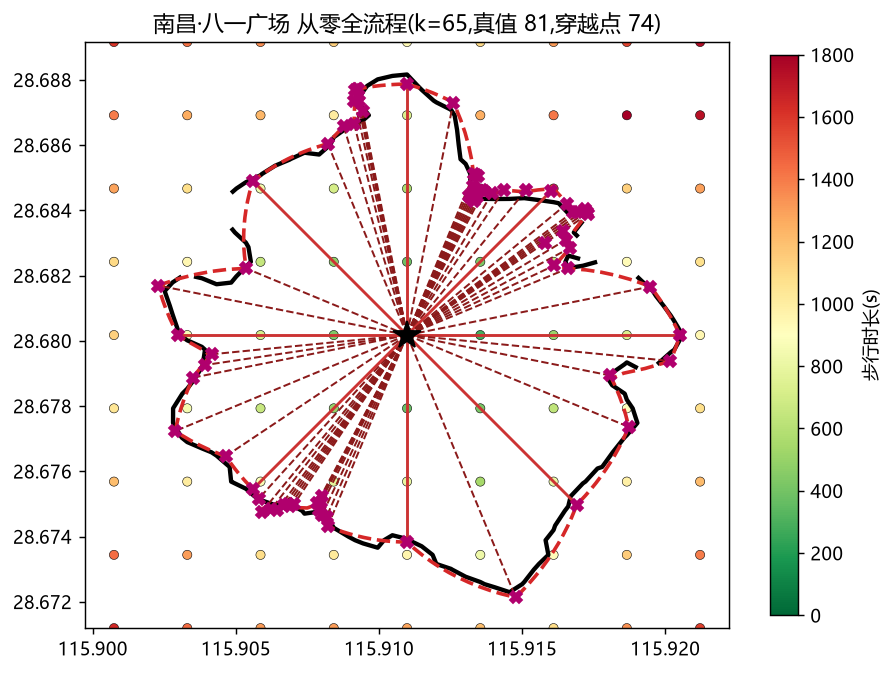

In [13]:
# S10 成图:射线/多边形/重建场/真值点/穿越点 一图流
fig, ax = plt.subplots(figsize=(8, 8), dpi=130)
X = np.array(gx).reshape(41, 41); Y = np.array(gy).reshape(41, 41)
Z = np.ma.masked_invalid(np.array(gz).reshape(41, 41))
ax.contour(X, Y, Z, levels=[TH], colors=['k'], linewidths=[2.4])
for b in sorted(radii):
    p = dest_at(CENTER[1], CENTER[0], b, radii[b])
    ax.plot([CENTER[1], p[1]], [CENTER[0], p[0]],
            color='#cc3333' if abs(b/45-round(b/45))<0.01 else '#8b1a1a',
            lw=1.6 if abs(b/45-round(b/45))<0.01 else 1.1,
            ls='-' if abs(b/45-round(b/45))<0.01 else '--')
xs, ys = [], []
for i2 in range(0, 361, 2):
    b = i2 % 360
    p = dest_at(CENTER[1], CENTER[0], b, r_at(b, radii))
    xs.append(p[1]); ys.append(p[0])
ax.plot(xs, ys, '--', color='#d62728', lw=2)
sc = ax.scatter([p[1] for p in g], [p[0] for p in g], c=tg, cmap='RdYlGn_r',
                vmin=0, vmax=1800, s=26, edgecolors='k', linewidths=.3)
for b, d in cross:
    p = dest_at(CENTER[1], CENTER[0], b, d)
    ax.plot(p[1], p[0], 'X', color='#b0006d', ms=7)
ax.plot(CENTER[1], CENTER[0], 'k*', ms=16)
ax.set_aspect(1/math.cos(math.radians(CENTER[0])))
plt.colorbar(sc, ax=ax, shrink=.7, label='步行时长(s)')
ax.set_title(f'南昌·八一广场 从零全流程(k={len(radii)},真值 {len(g)},穿越点 {len(cross)})')
out = os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'experiments', 'results', 'maps', 'nanchang_demo.png'))
fig.savefig(out, dpi=130, bbox_inches='tight')
print('已保存', out)

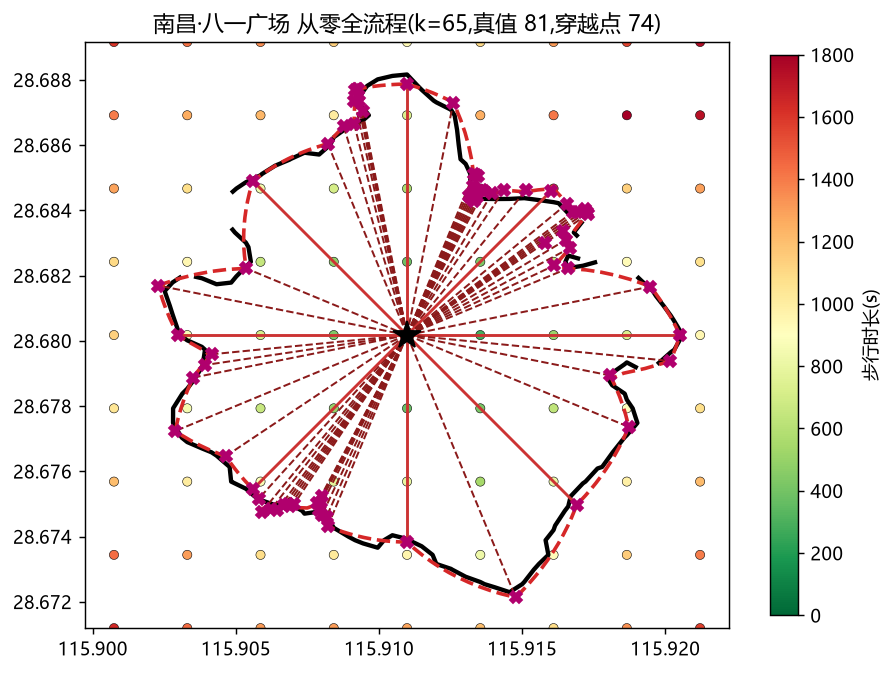

In [14]:
from IPython.display import Image
Image(out)

In [15]:
# S11 台阶结算 + 与十五城经验对比
req, pairs = ledger()
rows = []
for slug in ['harbin', 'kunshan', 'guilin']:
    d = json.load(open(os.path.abspath(os.path.join(
        os.getcwd(), '..', '..', 'experiments', 'results', 'e10_boundary',
        f'e10x_{slug}.json')), encoding='utf-8'))
    rows.append({'参照': d['city'], '射线': d['rays'], '总对数(含真值)': d['pairs_used']})
cmp = pd.DataFrame(rows)
display(cmp)
print(f"本演示实际消耗:{req} 次请求 / {pairs} 对")
print("重跑本 notebook:缓存命中,新增≈0(产品'二跑零调用'特性)")

,参照,射线,总对数(含真值)
0,哈尔滨·道外,62,480
1,昆山·人民路,23,368
2,桂林·东西巷,63,543


本演示实际消耗:111 次请求 / 111 对
重跑本 notebook:缓存命中,新增≈0(产品'二跑零调用'特性)


## 收尾说明

- 产物与十五城同 schema,可直接并入 `plot_maps.py` 的 CITIES 表与指标管线
- 生产化入口:`python experiments/pipeline.py --live --addr "..."`(docs/12)
- 全部中间结果(缓存/台账/图)落盘可审计;重跑零成本